# Olist E-Commerce: Customer Retention & Business Intelligence
**Main business question:** are customers acquired in 2017 still buying in 2018?

For this project, I am working with the Brazilian E-Commerce Public Dataset by Olist. My goal is to understand customer purchasing behavior and see what the transaction data can tell us about customer retention and business performance.

I will start by preparing the data and building a SQL Star Schema. Then, I will use Python and Pandas to analyze customer cohorts, calculate historical customer value, and investigate delivery performance and customer reviews.

I will also identify the highest-revenue customers and prepare the results for an interactive Power BI dashboard.

**What I want to investigate**

1. Customer behavior: Are customers making more than one purchase, or are most of them buying only once?

2. Customer retention: How does the percentage of returning customers change over the months following their first purchase?

3. Customer value: How much revenue does each customer generate, and how does this value develop across cohorts?

4. Delivery performance: Is there a relationship between delivery time and customer review scores?

5. High-value customers: Do a small number of customers contribute a significant share of total revenue?

**Tools**

Python, Pandas, NumPy, SQLite, SQL, Matplotlib, Seaborn, and Power BI.

## 1. Setup & load data

In [2]:
import os, sqlite3
import numpy as np, pandas as pd
import seaborn as sns, matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

# --- Locate the data (Kaggle first, then Colab via kagglehub) ---
KAGGLE_PATH = "/kaggle/input/brazilian-ecommerce/"
if os.path.exists(KAGGLE_PATH):
    DATA = KAGGLE_PATH
else:
    !pip -q install kagglehub
    import kagglehub
    DATA = kagglehub.dataset_download("olistbr/brazilian-ecommerce") + "/"
print("Data folder:", DATA)

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
Data folder: /kaggle/input/brazilian-ecommerce/


In [3]:
date_cols = ["order_purchase_timestamp", "order_approved_at",
             "order_delivered_carrier_date", "order_delivered_customer_date",
             "order_estimated_delivery_date"]

customers = pd.read_csv(DATA + "olist_customers_dataset.csv")
orders    = pd.read_csv(DATA + "olist_orders_dataset.csv", parse_dates=date_cols)
payments  = pd.read_csv(DATA + "olist_order_payments_dataset.csv")
reviews   = pd.read_csv(DATA + "olist_order_reviews_dataset.csv")

for name, t in [("customers", customers), ("orders", orders),
                ("payments", payments), ("reviews", reviews)]:
    print(f"{name:10s} {t.shape}")

customers  (99441, 5)
orders     (99441, 8)
payments   (103886, 5)
reviews    (99224, 7)


## 2. Understanding the Data and Checking Potential Problems

Before joining the tables, I want to understand how the data is structured. There are a few details in this dataset that could affect the accuracy of the analysis if I ignore them.

**First, customer identification.** The dataset contains both `customer_id` and `customer_unique_id`. A customer can have different customer IDs across orders, so I will use `customer_unique_id` when I need to identify the same person across multiple purchases.

**Second, payments.** An order can have more than one payment record. If I directly join payments to orders, the same order could appear multiple times and its revenue could be counted more than once. I will therefore aggregate payment records at the order level before joining them.

**Third, reviews.** Some orders have multiple review records. I need to account for this when calculating average review scores so that joining the review table does not increase the number of order rows.

I will also inspect order statuses and the available date range to understand which transactions are included in the analysis.

In [4]:
print("customer_id unique        :", customers.customer_id.nunique())
print("customer_unique_id unique :", customers.customer_unique_id.nunique())
print("Orders with >1 payment row:", (payments.groupby("order_id").size() > 1).sum())
print("Orders with >1 review     :", (reviews.groupby("order_id").size() > 1).sum())
print()
print(orders.order_status.value_counts())
print()
print("Date range:", orders.order_purchase_timestamp.min(), "->", orders.order_purchase_timestamp.max())

print("\n--- DATA QUALITY CHECKS ---")

print("Missing purchase timestamps:",
      orders["order_purchase_timestamp"].isna().sum())

print("Missing customer unique IDs:",
      customers["customer_unique_id"].isna().sum())

print("Missing payment values:",
      payments["payment_value"].isna().sum())

print("Duplicate order IDs:",
      orders["order_id"].duplicated().sum())

print("Orders without a customer:",
      (~orders["customer_id"].isin(
          customers["customer_id"]
      )).sum())

customer_id unique        : 99441
customer_unique_id unique : 96096
Orders with >1 payment row: 2961
Orders with >1 review     : 547

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Date range: 2016-09-04 21:15:19 -> 2018-10-17 17:30:18

--- DATA QUALITY CHECKS ---
Missing purchase timestamps: 0
Missing customer unique IDs: 0
Missing payment values: 0
Duplicate order IDs: 0
Orders without a customer: 0


## 3. Building the Star Schema Using SQL

Now that I have checked the main data issues, I can prepare the tables for analysis.

Instead of merging everything into one large table immediately, I will build a simple Star Schema. This makes the data model easier to understand and helps avoid duplication when combining information from different sources.

The model will contain one central fact table and three dimension tables:

- **fact_orders:** contains order-level information such as payment value, delivery time, and review score.
- **dim_customer:** contains customer information, including city and state.
- **dim_date:** contains date information that can be used for time-based analysis.
- **dim_payment_type:** contains the available payment methods.

The grain of the fact table will be one row per order. This is important because I want each order to be counted only once.

I will first load the original tables into SQLite as staging tables, then use SQL queries to create the dimensions and fact table.

In [6]:
conn = sqlite3.connect("olist.db")
customers.to_sql("stg_customers", conn, if_exists="replace", index=False)
orders.to_sql("stg_orders",       conn, if_exists="replace", index=False)
payments.to_sql("stg_payments",   conn, if_exists="replace", index=False)
reviews.to_sql("stg_reviews",     conn, if_exists="replace", index=False)
print("Staging tables loaded.")

Staging tables loaded.


### 3.1 Creating the Dimension Tables

I will start by creating the dimension tables that describe the customers, dates, and payment methods.

For the customer dimension, I use `customer_unique_id` as the customer key so that the same person is represented by one customer record.

For the payment dimension, I create a unique key for each payment type. This will allow me to connect payment information to the fact table without repeating the payment type as a descriptive field in every analytical relationship.

I also create a date dimension containing the year, quarter, month, and year-month. This will be useful later when analyzing trends and comparing customer activity over time.

One simplification in this model is that each customer is assigned one city and state. This is a customer-level location attribution, not a history of every address used across their orders.

In [11]:
conn.executescript("""
DROP TABLE IF EXISTS dim_customer;

CREATE TABLE dim_customer AS
WITH ranked_customers AS (
    SELECT
        customer_unique_id AS customer_key,
        customer_state AS state,
        customer_city AS city,
        customer_id,
        ROW_NUMBER() OVER (
            PARTITION BY customer_unique_id
            ORDER BY customer_id
        ) AS rn
    FROM stg_customers
)
SELECT
    customer_key,
    state,
    city
FROM ranked_customers
WHERE rn = 1;


DROP TABLE IF EXISTS dim_payment_type;

CREATE TABLE dim_payment_type AS
SELECT
    ROW_NUMBER() OVER (
        ORDER BY payment_type
    ) AS payment_type_key,
    payment_type
FROM (
    SELECT DISTINCT payment_type
    FROM stg_payments
);
""")

### 3.2 Creating the Fact Table

Now I will build the central fact table by connecting orders to the customer, payment, and review information.

There are a few transformations I need to perform before joining the tables:

- I aggregate all payment records belonging to the same order to obtain one total payment value.
- I select the main payment type for each order based on the highest individual payment amount.
- I calculate the average review score when an order has multiple review records.
- I use `customer_unique_id` to connect orders to the actual customer.

I also exclude canceled and unavailable orders because they do not represent completed purchasing activity.

The final table should contain one row per order. I will verify this in the next step rather than assuming that the joins worked correctly.

In [12]:
conn.executescript("""
DROP TABLE IF EXISTS fact_orders;

CREATE TABLE fact_orders AS

WITH pay AS (
    SELECT
        order_id,
        SUM(payment_value) AS payment_value,
        MAX(payment_installments) AS installments,
        COUNT(*) AS n_payments
    FROM stg_payments
    GROUP BY order_id
),

main_type AS (
    SELECT order_id, payment_type
    FROM (
        SELECT
            order_id,
            payment_type,
            ROW_NUMBER() OVER (
                PARTITION BY order_id
                ORDER BY payment_value DESC, payment_type
            ) AS rn
        FROM stg_payments
    )
    WHERE rn = 1
),

rev AS (
    SELECT
        order_id,
        AVG(review_score) AS review_score
    FROM stg_reviews
    GROUP BY order_id
)

SELECT
    o.order_id,
    c.customer_unique_id AS customer_key,
    DATE(o.order_purchase_timestamp) AS date_key,

    pt.payment_type_key,

    o.order_status,

    COALESCE(p.payment_value, 0) AS payment_value,

    p.installments,
    p.n_payments,

    r.review_score,

    julianday(o.order_delivered_customer_date)
    - julianday(o.order_purchase_timestamp)
    AS delivery_days

FROM stg_orders o

JOIN stg_customers c
    ON c.customer_id = o.customer_id

LEFT JOIN pay p
    ON p.order_id = o.order_id

LEFT JOIN main_type m
    ON m.order_id = o.order_id

LEFT JOIN dim_payment_type pt
    ON pt.payment_type = m.payment_type

LEFT JOIN rev r
    ON r.order_id = o.order_id

WHERE o.order_status = 'delivered';
""")

### 3.3 Validating the Data Model

Before using the fact table for analysis, I want to make sure that the transformations did not introduce any duplication.

The most important check here is comparing the total number of rows with the number of distinct order IDs. If the numbers are different, it means that some orders have been duplicated during the joins.

I will also compare the revenue in the fact table with the original payment data and check whether every customer in the fact table has a corresponding record in the customer dimension.

These checks help me confirm that the model is consistent enough to use for the following analyses.

In [14]:
print("\n--- STAR SCHEMA VALIDATION ---")

print("Fact table rows:",
      pd.read_sql(
          "SELECT COUNT(*) n FROM fact_orders",
          conn
      ).n[0])

print("Delivered orders:",
      pd.read_sql(
          "SELECT COUNT(*) n FROM fact_orders",
          conn
      ).n[0])

print("Orders without a payment:",
      pd.read_sql("""
          SELECT COUNT(*) n
          FROM fact_orders
          WHERE payment_value = 0
      """, conn).n[0])

print("Missing customer keys:",
      pd.read_sql("""
          SELECT COUNT(*) n
          FROM fact_orders f
          LEFT JOIN dim_customer d
          ON f.customer_key = d.customer_key
          WHERE d.customer_key IS NULL
      """, conn).n[0])


--- STAR SCHEMA VALIDATION ---
Fact table rows: 96478
Delivered orders: 96478
Orders without a payment: 1
Missing customer keys: 0


## 4. Customer Cohort Analysis

Now I want to look beyond total revenue and understand whether customers actually come back to make additional purchases.

For this, I will use cohort analysis. A cohort is simply a group of customers who share the same starting point. In this case, I will group customers according to the month of their first purchase.

I will calculate three things:

1. **Cohort month:** the month in which a customer made their first purchase.
2. **Cohort index:** the number of calendar months between the customer's first purchase month and a subsequent purchase month.
3. **Retention rate:** the percentage of customers from the original cohort who made a purchase in a particular subsequent month.

For example, customers who made their first purchase in January 2017 belong to the January 2017 cohort. If some of them purchase again in February, they will be counted in Month 1.

I will use unique customer counts so that a customer who places several orders in the same month is still counted only once for that month's retention.

The purpose of the heatmap is to make it easier to compare retention across different acquisition months and identify when customer activity starts to decline.

In [16]:
df = pd.read_sql("SELECT order_id, customer_key, date_key, payment_value FROM fact_orders",
                 conn, parse_dates=["date_key"])

df["order_month"]  = df.date_key.dt.to_period("M")
df["cohort_month"] = df.groupby("customer_key")["order_month"].transform("min")
df["cohort_index"] = ((df.order_month.dt.year  - df.cohort_month.dt.year) * 12
                    + (df.order_month.dt.month - df.cohort_month.dt.month))
df.head()

,order_id,customer_key,date_key,payment_value,order_month,cohort_month,cohort_index
0,e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,2017-10-02,38.71,2017-10,2017-09,1
1,53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,2018-07-24,141.46,2018-07,2018-07,0
2,47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,2018-08-08,179.12,2018-08,2018-08,0
3,949d5b44dbf5de918fe9c16f97b45f8a,7c142cf63193a1473d2e66489a9ae977,2017-11-18,72.20,2017-11,2017-11,0
4,ad21c59c0840e6cb83a9ceb5573f8159,72632f0f9dd73dfee390c9b22eb56dd6,2018-02-13,28.62,2018-02,2018-02,0


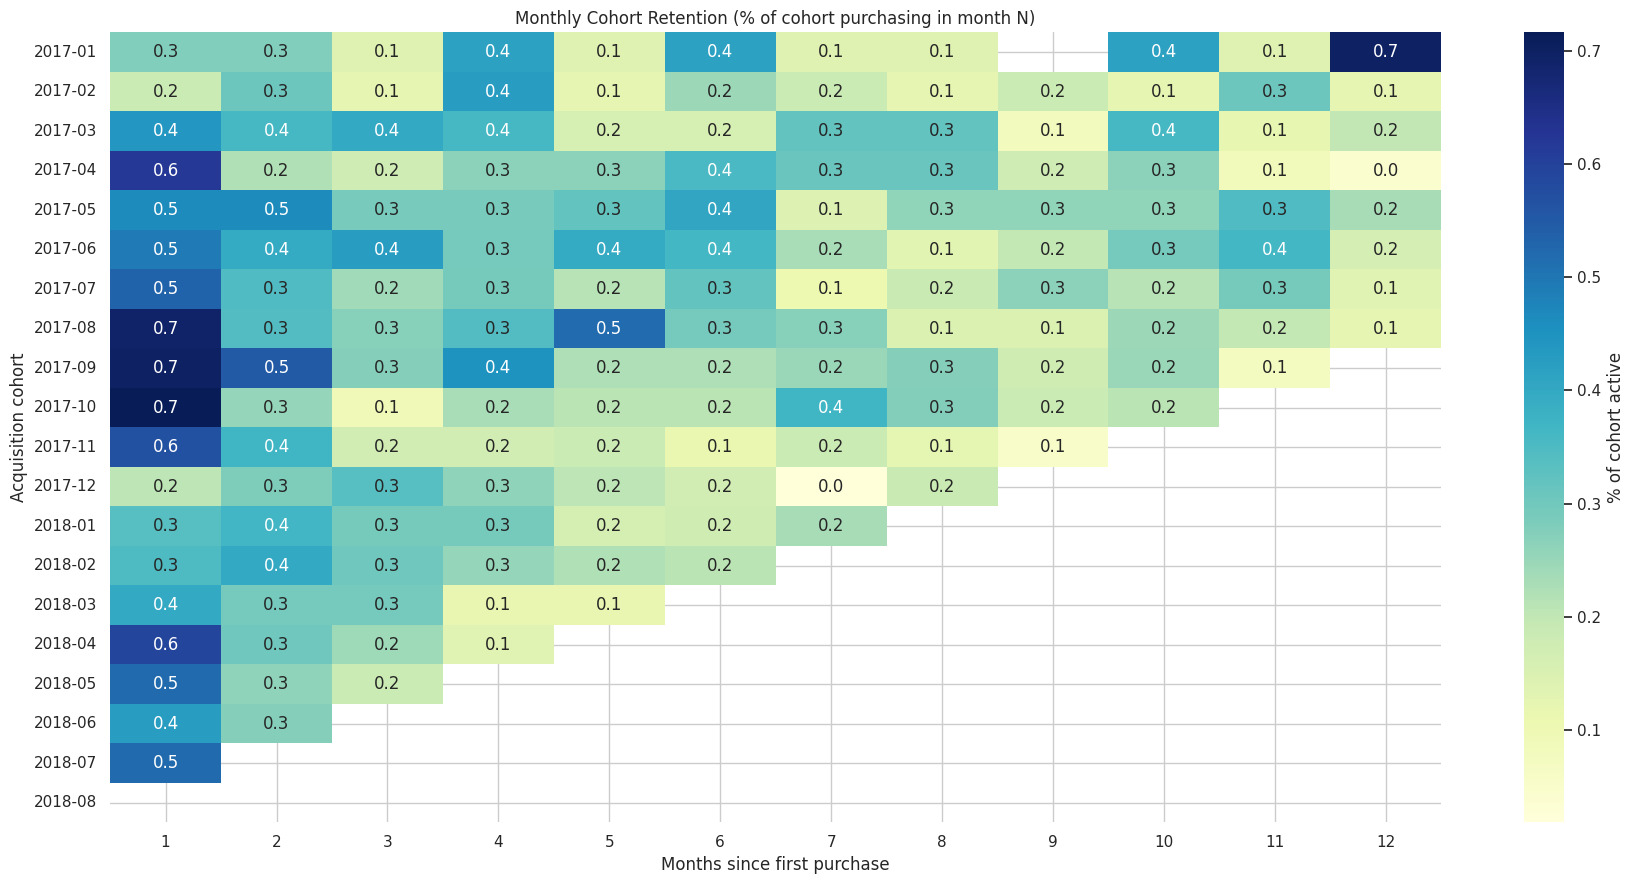

In [17]:
cohort_counts = (df.groupby(["cohort_month", "cohort_index"])["customer_key"]
                   .nunique().unstack())
retention = cohort_counts.divide(cohort_counts[0], axis=0) * 100

# 2016 is tiny and late 2018 is incomplete -> keep reliable cohorts only
retention = retention.loc["2017-01":"2018-08"]
retention.index = retention.index.astype(str)

plt.figure(figsize=(18, 9))
sns.heatmap(retention.iloc[:, 1:13], annot=True, fmt=".1f", cmap="YlGnBu",
            cbar_kws={"label": "% of cohort active"})
plt.title("Monthly Cohort Retention (% of cohort purchasing in month N)")
plt.xlabel("Months since first purchase")
plt.ylabel("Acquisition cohort")
plt.tight_layout(); plt.show()

I have excluded Month 0 from the heatmap because it represents the original acquisition month. By definition, all customers in a cohort are active in that month, so retention is always 100%.

Showing Month 0 would make the color scale less useful. I am more interested in what happens after acquisition, especially during the first few months.

I also limit the displayed cohorts because customers acquired near the end of the dataset do not have enough historical months available for a fair comparison.

### 4.1 Answering the CEO's Question: Are 2017 Customers Still Buying in 2018?

The heatmap helps me understand retention month by month, but the CEO's question is more specific.

I want to identify all customers whose first purchase occurred in 2017 and check whether they placed at least one additional order during 2018.

For this calculation, I will:

1. Identify customers whose first purchase month belongs to 2017.
2. Check their orders during 2018.
3. Count how many of these customers returned.
4. Calculate the percentage of returning customers relative to the original 2017 customer group.

This gives me a direct answer to the business question.

One important distinction: this metric measures whether a customer purchased at least once during the following calendar year. It is not the same as Month 12 cohort retention, because customers acquired in different months have different amounts of time between acquisition and the end of 2018.

In [18]:
first_month = df.groupby("customer_key").cohort_month.min()
c2017 = first_month[first_month.dt.year == 2017].index

bought_2018 = (df[df.customer_key.isin(c2017) & (df.date_key.dt.year == 2018)]
                 .customer_key.nunique())

print(f"Customers acquired in 2017 : {len(c2017):,}")
print(f"...who bought again in 2018: {bought_2018:,} ({bought_2018/len(c2017):.2%})")

Customers acquired in 2017 : 42,131
...who bought again in 2018: 643 (1.53%)


In [19]:
customers_2018 = df[
    df.customer_key.isin(c2017)
    & (df.date_key.dt.year == 2018)
]

repeat_2018 = (
    customers_2018.groupby("customer_key")["order_id"]
    .nunique()
)

purchased_once = (repeat_2018 == 1).sum()
purchased_multiple = (repeat_2018 >= 2).sum()

print("\n--- 2017 CUSTOMER BEHAVIOR IN 2018 ---")

print("Purchased at least once:",
      bought_2018)

print("Purchased exactly once:",
      purchased_once)

print("Purchased multiple times:",
      purchased_multiple)

print("Percentage of 2018 returners who purchased multiple times:",
      f"{purchased_multiple / bought_2018:.2%}")


--- 2017 CUSTOMER BEHAVIOR IN 2018 ---
Purchased at least once: 643
Purchased exactly once: 593
Purchased multiple times: 50
Percentage of 2018 returners who purchased multiple times: 7.78%


## 5. Customer Lifetime Value (CLV)

After looking at customer retention, I want to understand how much revenue customers generate.

For this project, I will focus on historical customer value rather than trying to predict future purchases.

I will calculate:

- **Historical customer revenue:** the total payment value generated by each customer across their observed orders.
- **Average historical revenue per customer:** the average of these customer-level revenue totals.
- **Repeat-customer rate:** the percentage of customers who placed more than one order.
- **Cohort-based cumulative revenue:** the average cumulative revenue generated per customer in each cohort over the months following their first purchase.

The cohort analysis will help me compare whether customer value develops differently depending on the month in which customers were first acquired.

I will refer to these measures as historical revenue and historical CLV throughout the analysis, since the dataset does not provide a predictive model of future customer behavior.

In [20]:
clv = df.groupby("customer_key").agg(
        orders=("order_id", "nunique"),
        revenue=("payment_value", "sum"),
        first_order=("date_key", "min"),
        last_order=("date_key", "max"))

print(clv.revenue.describe().round(2))
print("\nRepeat-customer rate (2+ orders):", f"{(clv.orders > 1).mean():.2%}")
print("Average CLV (BRL):", round(clv.revenue.mean(), 2))

count    93358.00
mean       165.20
std        226.31
min          0.00
25%         63.05
50%        107.78
75%        182.56
max      13664.08
Name: revenue, dtype: float64

Repeat-customer rate (2+ orders): 3.00%
Average CLV (BRL): 165.2


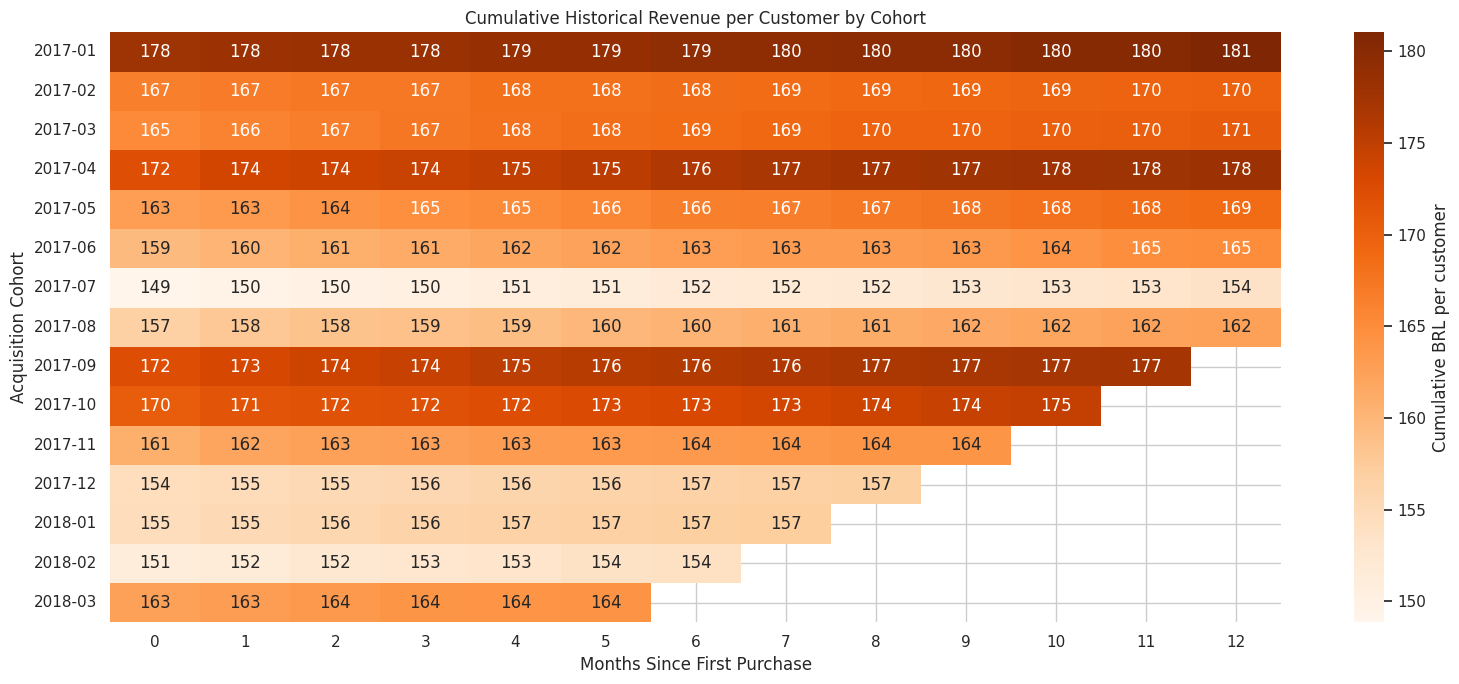

In [21]:
rev_by_cohort = (
    df.groupby(["cohort_month", "cohort_index"])
      ["payment_value"]
      .sum()
      .unstack()
)

last_month = df["order_month"].max()

# Calculate the maximum observable age for each cohort
max_age = (
    (last_month.year - rev_by_cohort.index.year) * 12
    + (last_month.month - rev_by_cohort.index.month)
)

# Fill missing purchase activity with zero initially
# because an observed month with no purchases has zero revenue.
rev_by_cohort = rev_by_cohort.fillna(0)

# Calculate cumulative revenue per customer
cum_clv = (
    rev_by_cohort.cumsum(axis=1)
    .divide(cohort_counts[0], axis=0)
)

# Mask months that have not yet been observed
for cohort, age in zip(cum_clv.index, max_age):
    cum_clv.loc[
        cohort,
        cum_clv.columns > age
    ] = np.nan

cum_clv = cum_clv.loc["2017-01":"2018-03"]

cum_clv.index = cum_clv.index.astype(str)

plt.figure(figsize=(16, 7))

sns.heatmap(
    cum_clv.iloc[:, :13],
    annot=True,
    fmt=".0f",
    cmap="Oranges",
    cbar_kws={
        "label": "Cumulative BRL per customer"
    }
)

plt.title("Cumulative Historical Revenue per Customer by Cohort")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Acquisition Cohort")

plt.tight_layout()
plt.show()

The heatmap shows how cumulative revenue per customer develops over time for each acquisition cohort.

I want to compare the initial revenue generated during Month 0 with the cumulative value reached in later months, especially Month 12.

If the cumulative value increases only slightly after Month 0, it suggests that most of the observed revenue was generated during the initial purchasing period.

If it continues to increase, this indicates that customers in that cohort generated additional revenue through subsequent purchases.

I also need to be careful when interpreting the later months: recent cohorts have fewer observable months than older ones. Missing future periods should not be interpreted as zero revenue.

## 6.  Delivery Time and Customer Review Scores

Customer satisfaction is another important part of the e-commerce experience. I want to investigate whether the time customers wait for their orders is associated with the reviews they leave.

I will use the delivery time calculated from the purchase date and the date the order was delivered to the customer.

First, I will calculate the average delivery time and average review score for each state. Then, I will compare these two measures to see whether states with longer delivery times tend to have lower review scores.

I will also calculate the Spearman correlation at two levels:

- **Order level:** to examine the relationship between delivery time and review score across individual orders.
- **State level:** to compare the relationship between average delivery time and average review score across states.

Finally, I will group orders into delivery-time intervals to see how average review scores change as delivery takes longer.

This analysis can help identify possible delivery-related customer experience issues. However, correlation alone does not prove that delivery time is the direct cause of a lower review score.

In [22]:
d = pd.read_sql('''
    SELECT f.order_id, f.delivery_days, f.review_score, c.state
    FROM fact_orders f
    JOIN dim_customer c ON c.customer_key = f.customer_key
    WHERE f.order_status = 'delivered'
      AND f.delivery_days IS NOT NULL
      AND f.review_score  IS NOT NULL''', conn)

by_state = (d.groupby("state")
             .agg(avg_delivery_days=("delivery_days", "mean"),
                  avg_review=("review_score", "mean"),
                  orders=("order_id", "count"))
             .reset_index().sort_values("avg_delivery_days"))
by_state.round(2)

,state,avg_delivery_days,avg_review,orders
25,SP,8.75,4.25,40265
17,PR,11.97,4.24,4900
10,MG,11.99,4.19,11283
6,DF,12.96,4.13,2069
23,SC,14.87,4.13,3520
18,RJ,15.24,3.96,12205
22,RS,15.28,4.19,5328
8,GO,15.55,4.11,1949
7,ES,15.61,4.08,1968
11,MS,15.62,4.16,698


Order-level Spearman : -0.235
State-level Spearman : -0.461


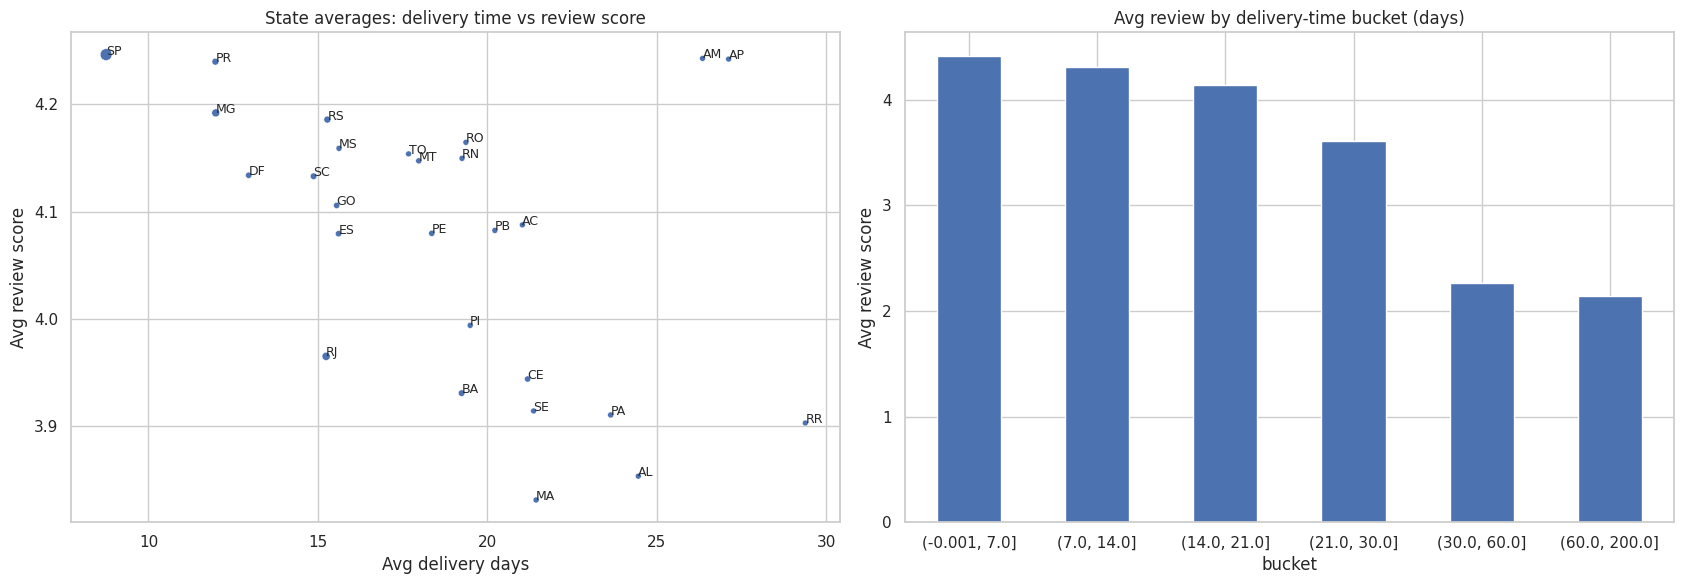

In [24]:
print("Order-level Spearman :", round(d.delivery_days.corr(d.review_score, method="spearman"), 3))
print("State-level Spearman :", round(by_state.avg_delivery_days.corr(by_state.avg_review, method="spearman"), 3))

fig, ax = plt.subplots(1, 2, figsize=(17, 6))

sns.scatterplot(data=by_state, x="avg_delivery_days", y="avg_review",
                size="orders", legend=False, ax=ax[0])
for _, r in by_state.iterrows():
    ax[0].annotate(r.state, (r.avg_delivery_days, r.avg_review), fontsize=9)
ax[0].set_title("State averages: delivery time vs review score")
ax[0].set_xlabel("Avg delivery days"); ax[0].set_ylabel("Avg review score")

d["bucket"] = pd.cut(d.delivery_days, [0, 7, 14, 21, 30, 60, 200], include_lowest=True)
d.groupby("bucket", observed=True).review_score.mean().plot(kind="bar", ax=ax[1], rot=0)
ax[1].set_title("Avg review by delivery-time bucket (days)")
ax[1].set_ylabel("Avg review score")
plt.tight_layout(); plt.show()

## 7.  Identifying High-Value Customers

For the final bonus analysis, I want to identify the customers who contribute the most revenue.

I will rank customers according to their total historical revenue and identify the highest-value group, using the 99th percentile as the threshold.

Then, I will compare this group with the remaining customers in terms of:

- Total revenue contribution.
- Average revenue per customer.
- Average number of orders.
- Percentage of customers who placed only one order.

I am particularly interested in whether high revenue is associated with repeat purchasing or whether some customers generate a large amount of revenue from a single transaction.

This distinction matters because a customer who spends a lot once is not necessarily a loyal customer. Understanding this group could help identify opportunities for more targeted retention strategies.

In [25]:
n_top = int(np.ceil(len(clv) * 0.01))

power = (
    clv.sort_values(
        ["revenue"],
        ascending=False,
        kind="stable"
    )
    .head(n_top)
)

rest = clv.drop(power.index)

print("Total customers:", len(clv))
print("Top 1% customers:", len(power))

print(
    "Revenue contribution:",
    f"{power.revenue.sum() / clv.revenue.sum():.2%}"
)

print(
    "Average revenue:",
    f"R$ {power.revenue.mean():,.2f}"
)

print(
    "One-time buyers:",
    f"{(power.orders == 1).mean():.2%}"
)

Total customers: 93358
Top 1% customers: 934
Revenue contribution: 10.35%
Average revenue: R$ 1,708.97
One-time buyers: 92.83%


In [26]:
dim_cust = pd.read_sql("SELECT customer_key, state FROM dim_customer", conn).set_index("customer_key")
top_states = power.join(dim_cust).state.value_counts().head(5)
print(top_states)
power.head(10)

state
SP    295
RJ    123
MG    104
PR     55
RS     51
Name: count, dtype: int64


,orders,revenue,first_order,last_order
customer_key,,,,
0a0a92112bd4c708ca5fde585afaa872,1,13664.08,2017-09-29,2017-09-29
da122df9eeddfedc1dc1f5349a1a690c,2,7571.63,2017-04-01,2017-04-01
763c8b1c9c68a0229c42c9fc6f662b93,1,7274.88,2018-07-15,2018-07-15
dc4802a71eae9be1dd28f5d788ceb526,1,6929.31,2017-02-12,2017-02-12
459bef486812aa25204be022145caa62,1,6922.21,2018-07-25,2018-07-25
ff4159b92c40ebe40454e3e6a7c35ed6,1,6726.66,2017-05-24,2017-05-24
4007669dec559734d6f53e029e360987,1,6081.54,2017-11-24,2017-11-24
eebb5dda148d3893cdaf5b5ca3040ccb,1,4764.34,2017-04-18,2017-04-18
48e1ac109decbb87765a3eade6854098,1,4681.78,2018-06-22,2018-06-22


In [27]:
customer_summary = (
    clv.reset_index()
    .copy()
)

customer_summary["customer_segment"] = np.where(
    customer_summary["orders"] > 1,
    "Repeat Customer",
    "One-Time Customer"
)

customer_summary["is_power_user"] = (
    customer_summary["customer_key"].isin(power.index)
)

customer_summary["cohort_month"] = (
    customer_summary["first_order"]
    .dt.to_period("M")
    .astype(str)
)

customer_summary["first_order"] = (
    customer_summary["first_order"].astype(str)
)

customer_summary["last_order"] = (
    customer_summary["last_order"].astype(str)
)

print(customer_summary.head())

print("\nCustomer summary:", customer_summary.shape)

                       customer_key  orders  revenue first_order  last_order  \
0  0000366f3b9a7992bf8c76cfdf3221e2       1   141.90  2018-05-10  2018-05-10   
1  0000b849f77a49e4a4ce2b2a4ca5be3f       1    27.19  2018-05-07  2018-05-07   
2  0000f46a3911fa3c0805444483337064       1    86.22  2017-03-10  2017-03-10   
3  0000f6ccb0745a6a4b88665a16c9f078       1    43.62  2017-10-12  2017-10-12   
4  0004aac84e0df4da2b147fca70cf8255       1   196.89  2017-11-14  2017-11-14   

    customer_segment  is_power_user cohort_month  
0  One-Time Customer          False      2018-05  
1  One-Time Customer          False      2018-05  
2  One-Time Customer          False      2017-03  
3  One-Time Customer          False      2017-10  
4  One-Time Customer          False      2017-11  

Customer summary: (93358, 8)


## 8. Preparing the Data for Power BI

After completing the analysis, I will export the SQL dimension tables, fact table, and analytical results into CSV files.

The goal is to use these prepared datasets in Power BI to build an interactive report that presents the main findings in a more accessible way.

I will keep the original Star Schema tables separate rather than exporting everything as one large merged file. This allows me to preserve the data model and create the appropriate relationships inside Power BI.

I will also export the cohort retention, cohort revenue, delivery performance, and high-value customer results as separate analytical datasets.

In Power BI, the three dimension tables will be connected to the central fact table using one-to-many relationships. The aggregated cohort tables will be treated as separate analytical outputs because they have a different level of detail from the order-level fact table.

In [28]:
retention_export = (
    retention.rename_axis("cohort_month")
    .reset_index()
    .melt(
        id_vars="cohort_month",
        var_name="cohort_index",
        value_name="retention_pct"
    )
)

retention_export["cohort_index"] = (
    retention_export["cohort_index"].astype(int)
)

retention_export["cohort_size"] = (
    retention_export["cohort_month"]
    .map(cohort_counts[0].to_dict())
)

clv_export = (
    cum_clv.rename_axis("cohort_month")
    .reset_index()
    .melt(
        id_vars="cohort_month",
        var_name="cohort_index",
        value_name="cumulative_revenue_per_customer"
    )
)

clv_export["cohort_index"] = (
    clv_export["cohort_index"].astype(int)
)

In [29]:
os.makedirs("star", exist_ok=True)

# Core Star Schema
for t in [
    "dim_customer",
    "dim_date",
    "dim_payment_type",
    "fact_orders"
]:
    pd.read_sql(
        f"SELECT * FROM {t}",
        conn
    ).to_csv(
        f"star/{t}.csv",
        index=False
    )

# Analytical datasets
retention_export.to_csv(
    "star/cohort_retention_long.csv",
    index=False
)

clv_export.to_csv(
    "star/cohort_clv_long.csv",
    index=False
)

customer_summary.to_csv(
    "star/customer_summary.csv",
    index=False
)

by_state.to_csv(
    "star/delivery_vs_review_by_state.csv",
    index=False
)

power.reset_index().to_csv(
    "star/power_users.csv",
    index=False
)

print("Exported files:")
print(os.listdir("star"))

Exported files:
['fact_orders.csv', 'power_users.csv', 'dim_payment_type.csv', 'cohort_clv_long.csv', 'cohort_retention_long.csv', 'dim_customer.csv', 'delivery_vs_review_by_state.csv', 'dim_date.csv', 'customer_summary.csv']


## Findings

- **CEO answer:** 1.54% of customers acquired in 2017 purchased again in 2018 (663 out of 43,029 customers). This indicates very low long-term customer return.

- **Retention:** Average retention across the displayed Month 1–Month 12 cohort cells is approximately **0.27%**. Retention is consistently low across the cohorts, suggesting that most customers do not make frequent repeat purchases.

- **CLV:** Average historical CLV is **R$165.69 per customer**. For the 2017 cohorts with a complete 12-month observation window, average cumulative revenue per customer increases from approximately **R$164.83 at Month 0 to R$169.38 at Month 11**. This suggests that most customer revenue is generated by the first purchase.

- **Delivery vs reviews:** Spearman correlation is **-0.235 at order level** and **-0.461 at state level**. The slowest states in the dataset include RR (29.39 days), AP (27.12 days), and AM (26.35 days). These results suggest an association between longer delivery times and lower review scores, although correlation does not prove causation.

- **Power users:** The top 1% of customers by revenue (950 customers) generate **10.3% of total revenue**. Their average revenue is R$1,713, compared with R$150 for other customers. However, **92.8% of these high-revenue customers made only one order**, showing that high spending does not necessarily mean customer loyalty.

- **Recommendations:**
  1. Develop post-purchase campaigns and personalized offers to encourage a second purchase.
  2. Focus retention efforts on customers after their first order, since most revenue is generated at acquisition.
  3. Investigate delivery performance in states with longer delivery times, especially where order volumes are sufficient.
  4. Give high-value, one-time buyers targeted incentives to return.
  5. Monitor monthly cohort retention, repeat-purchase rate, and revenue per customer to measure whether these actions improve customer loyalty.